# TIỀN XỬ LÝ DỮ LIỆU VÀ KỸ THUẬT ĐẶC TRƯNG
## Đồ án môn học: Dự đoán nhu cầu xe đạp công cộng (UCI Bike Sharing Dataset)

Sổ tay này thực hiện làm sạch dữ liệu, tạo đặc trưng, phân chia Train/Test và chuẩn hóa, chuẩn bị dữ liệu cho giai đoạn huấn luyện mô hình.

**Nguyên tắc xuyên suốt – Chống rò rỉ dữ liệu (Zero Data Leakage):** nhóm em chia các phép xử lý thành hai loại:
1. **Phép biến đổi không học tham số từ dữ liệu** (xóa cột, mã hóa $\sin/\cos$, tạo `is_rush_hour` theo quy tắc cố định, One-Hot với danh mục cố định): áp dụng độc lập trên từng dòng nên được thực hiện **trước** khi chia dữ liệu.
2. **Phép biến đổi có học tham số từ dữ liệu** (trung vị điền khuyết, ngưỡng IQR, kiểm định chọn lọc đặc trưng, K-Means, PCA, các bộ Scaler): **chỉ học trên tập Train**, sau đó áp dụng tham số đã học cho tập Test.

Biến mục tiêu `cnt` của tập Test được **giữ nguyên giá trị gốc** để kết quả đánh giá phản ánh đúng nhu cầu thực tế.

# 1. Khởi tạo môi trường và đọc dữ liệu

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42

# Đọc tập dữ liệu theo giờ gốc
df = pd.read_csv('../data/hour.csv')
print(f"Kích thước tập dữ liệu gốc: {df.shape[0]} dòng, {df.shape[1]} cột")
df.head()

Kích thước tập dữ liệu gốc: 17379 dòng, 17 cột


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


# 2. Loại bỏ các cột định danh và chống rò rỉ dữ liệu (Data Leakage)

Dựa trên kết quả phân tích dữ liệu (EDA), nhóm em thực hiện loại bỏ:
- **`instant` và `dteday`:** Chỉ là số thứ tự và ngày ghi nhận dạng chuỗi; thông tin thời gian hữu ích đã có trong `yr`, `mnth`, `weekday`, `hr`.
- **`casual` và `registered`:** Vì $cnt = casual + registered$. Nếu giữ lại, mô hình chỉ cần học phép cộng là đạt điểm tuyệt đối giả tạo, không có giá trị dự đoán thực tế.

In [2]:
drop_leakage_cols = ['instant', 'dteday', 'casual', 'registered']
df = df.drop(columns=drop_leakage_cols, errors='ignore')

print(f"Đã loại bỏ các cột: {drop_leakage_cols}")
print(f"Kích thước dữ liệu hiện tại: {df.shape}")

Đã loại bỏ các cột: ['instant', 'dteday', 'casual', 'registered']
Kích thước dữ liệu hiện tại: (17379, 13)


# 3. Loại bỏ đặc trưng đa cộng tuyến (atemp)

Ở bước khám phá dữ liệu, tương quan Pearson giữa `temp` (nhiệt độ thực tế) và `atemp` (nhiệt độ cảm nhận) xấp xỉ $0.99$ – mức **đa cộng tuyến rất cao** (chưa phải hoàn hảo nhưng gần như trùng lặp thông tin). Để các hệ số hồi quy ổn định và dễ diễn giải, nhóm em giữ lại biến đo lường khách quan `temp` và xóa `atemp`.

In [3]:
df = df.drop(columns=['atemp'], errors='ignore')
print("Đã loại bỏ cột 'atemp'.")
print(f"Kích thước dữ liệu hiện tại: {df.shape}")

Đã loại bỏ cột 'atemp'.
Kích thước dữ liệu hiện tại: (17379, 12)


# 4. Kỹ thuật tạo đặc trưng chu kỳ thời gian (Cyclical Feature Encoding)

Các biến `hr` (0–23), `mnth` (1–12), `weekday` (0–6) có bản chất tuần hoàn: 23h và 0h thực tế chỉ cách nhau 1 giờ, nhưng ở dạng số nguyên thì mô hình hiểu là cách nhau 23 đơn vị. Nhóm em ánh xạ chúng lên đường tròn đơn vị:
$$x_{\sin} = \sin\left(\frac{2\pi \cdot t}{T}\right), \quad x_{\cos} = \cos\left(\frac{2\pi \cdot t}{T}\right)$$
với $T = 24$ (giờ), $T = 12$ (tháng), $T = 7$ (thứ). Đây là phép biến đổi cố định theo từng dòng, không học tham số nên không gây rò rỉ dữ liệu.

In [4]:
df['hr_sin'] = np.sin(2 * np.pi * df['hr'] / 24)
df['hr_cos'] = np.cos(2 * np.pi * df['hr'] / 24)
df['mnth_sin'] = np.sin(2 * np.pi * df['mnth'] / 12)
df['mnth_cos'] = np.cos(2 * np.pi * df['mnth'] / 12)
df['weekday_sin'] = np.sin(2 * np.pi * df['weekday'] / 7)
df['weekday_cos'] = np.cos(2 * np.pi * df['weekday'] / 7)

print("Đã tạo 6 đặc trưng chu kỳ: hr_sin, hr_cos, mnth_sin, mnth_cos, weekday_sin, weekday_cos")
df[['hr', 'hr_sin', 'hr_cos', 'mnth', 'mnth_sin', 'mnth_cos']].head()

Đã tạo 6 đặc trưng chu kỳ: hr_sin, hr_cos, mnth_sin, mnth_cos, weekday_sin, weekday_cos


,hr,hr_sin,hr_cos,mnth,mnth_sin,mnth_cos
0,0,0.000000,1.000000,1,0.5,0.866025
1,1,0.258819,0.965926,1,0.5,0.866025
2,2,0.500000,0.866025,1,0.5,0.866025
3,3,0.707107,0.707107,1,0.5,0.866025
4,4,0.866025,0.500000,1,0.5,0.866025


# 5. Tạo đặc trưng mới: Giờ cao điểm (is_rush_hour)

Từ biểu đồ xu hướng 24 giờ ở bước EDA, nhu cầu tăng vọt vào các ngày làm việc (`workingday == 1`) ở khung sáng (7h–9h) và chiều tối (17h–19h). Nhóm em tạo biến nhị phân `is_rush_hour` theo **quy tắc cố định** về giờ hành chính (không tính từ `cnt`), nên có thể áp dụng trước khi chia dữ liệu.

In [5]:
df['is_rush_hour'] = ((df['workingday'] == 1) & (df['hr'].isin([7, 8, 9, 17, 18, 19]))).astype(int)

rush_count = df['is_rush_hour'].sum()
print(f"Số giờ cao điểm (is_rush_hour = 1): {rush_count} / {len(df)} giờ (chiếm {rush_count/len(df)*100:.1f}%)")

Số giờ cao điểm (is_rush_hour = 1): 2983 / 17379 giờ (chiếm 17.2%)


# 6. Mã hóa biến phân loại bằng One-Hot Encoding

`season` (4 mùa) và `weathersit` (4 loại thời tiết) là biến danh nghĩa. Nhóm em mã hóa One-Hot với **danh mục cố định** theo mô tả của UCI (1–4) và `drop_first=True` để tránh bẫy biến giả (Dummy Variable Trap). Cột `season` gốc được lưu riêng để phục vụ bước phân tích ngoại lai theo mùa.

*Lưu ý:* loại thời tiết `weathersit = 4` (mưa to, bão) chỉ xuất hiện rất ít lần trong dữ liệu, nên đặc trưng `weathersit_4` gần như hằng số và mô hình khó học được tác động của nó.

In [6]:
season_raw = df['season'].copy()   # giữ lại để tính ngưỡng ngoại lai theo mùa

for col in ['season', 'weathersit']:
    df[col] = pd.Categorical(df[col], categories=[1, 2, 3, 4])
df = pd.get_dummies(df, columns=['season', 'weathersit'], drop_first=True, dtype=int)

print(f"Số lần xuất hiện weathersit = 4: {df['weathersit_4'].sum()}")
print(f"Kích thước dữ liệu hiện tại: {df.shape[0]} dòng, {df.shape[1]} cột")
print(list(df.columns))

Số lần xuất hiện weathersit = 4: 3
Kích thước dữ liệu hiện tại: 17379 dòng, 23 cột
['yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'temp', 'hum', 'windspeed', 'cnt', 'hr_sin', 'hr_cos', 'mnth_sin', 'mnth_cos', 'weekday_sin', 'weekday_cos', 'is_rush_hour', 'season_2', 'season_3', 'season_4', 'weathersit_2', 'weathersit_3', 'weathersit_4']


# 7. Phân chia tập Huấn luyện / Kiểm tra (Train/Test Split)

Từ bước này trở đi, mọi phép xử lý có học tham số đều **chỉ được học trên tập Train**. Nhóm em chia dữ liệu **80% Train – 20% Test** với `random_state=42`.

*Hạn chế cần lưu ý:* dữ liệu là chuỗi thời gian theo giờ, nên chia ngẫu nhiên có thể đưa các giờ liền kề của cùng một ngày vào cả Train và Test, khiến kết quả đánh giá lạc quan hơn so với dự báo tương lai thực sự. Nhóm em sẽ thảo luận điểm này trong phần hạn chế và có thể bổ sung thí nghiệm chia theo thời gian.

In [7]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['cnt'])
y = df['cnt'].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
season_train = season_raw.loc[X_train.index]

print(f"Tập huấn luyện: {X_train.shape[0]} dòng ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"Tập kiểm tra:   {X_test.shape[0]} dòng ({X_test.shape[0]/len(df)*100:.1f}%)")

Tập huấn luyện: 13903 dòng (80.0%)
Tập kiểm tra:   3476 dòng (20.0%)


# 8. Xử lý 22 dòng có độ ẩm bằng 0 (hum == 0)

Do cảm biến trục trặc ngày 10/03/2011, có 22 dòng ghi nhận độ ẩm $0.00$. Nhóm em thay các giá trị này bằng **trung vị độ ẩm theo (tháng, giờ)**, trong đó bảng trung vị **chỉ được tính từ các dòng hợp lệ của tập Train**, rồi dùng chung bảng này để điền cho cả Train và Test.

In [8]:
valid_train = X_train[X_train['hum'] > 0]
median_hum_by_mnth_hr = valid_train.groupby(['mnth', 'hr'])['hum'].median()
hum_fallback = valid_train['hum'].median()

def fill_zero_hum(X_part):
    X_part = X_part.copy()
    mask = X_part['hum'] == 0
    keys = zip(X_part.loc[mask, 'mnth'], X_part.loc[mask, 'hr'])
    X_part.loc[mask, 'hum'] = [median_hum_by_mnth_hr.get(k, hum_fallback) for k in keys]
    return X_part

print(f"Số dòng hum == 0 trước xử lý -> Train: {(X_train['hum'] == 0).sum()}, Test: {(X_test['hum'] == 0).sum()}")
X_train = fill_zero_hum(X_train)
X_test = fill_zero_hum(X_test)
print(f"Số dòng hum == 0 sau xử lý   -> Train: {(X_train['hum'] == 0).sum()}, Test: {(X_test['hum'] == 0).sum()}")
print(f"Độ ẩm nhỏ nhất hiện tại      -> Train: {X_train['hum'].min():.4f}, Test: {X_test['hum'].min():.4f}")

Số dòng hum == 0 trước xử lý -> Train: 18, Test: 4
Số dòng hum == 0 sau xử lý   -> Train: 0, Test: 0
Độ ẩm nhỏ nhất hiện tại      -> Train: 0.0800, Test: 0.1500


# 9. Phân tích ngoại lai của biến mục tiêu bằng IQR (chỉ trên tập Train)

Ngoại lai theo IQR **không đồng nghĩa với dữ liệu sai**: phần lớn là các giờ tan tầm vào ngày đẹp trời – hành vi thuê xe có thật. Vì vậy nhóm em:
- **Giữ nguyên `cnt` gốc** cho cả Train và Test làm mục tiêu chính. Tập Test tuyệt đối không bị chỉnh sửa, để sai số đo được phản ánh đúng nhu cầu thực tế.
- Tính ngưỡng râu trên $Q_3 + 1.5 \times IQR$ theo từng mùa **chỉ từ tập Train**, và tạo thêm một phiên bản mục tiêu đã giới hạn trần `y_train_capped` (Capping/Winsorization) để **kiểm chứng bằng thực nghiệm** giả thuyết: *giới hạn trần ngoại lai có giúp các mô hình nhạy với sai số lớn (OLS, AdaBoost) tốt hơn hay không*, thay vì mặc định cắt bỏ các nhu cầu cao.

In [9]:
y_train_capped = y_train.copy()
outlier_rows = []
for s in sorted(season_train.unique()):
    idx = season_train.index[season_train == s]
    q1, q3 = y_train.loc[idx].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    n_out = (y_train.loc[idx] > upper).sum()
    y_train_capped.loc[idx] = y_train.loc[idx].clip(upper=upper)
    outlier_rows.append({'Mùa': int(s), 'Q1': q1, 'Q3': q3, 'Ngưỡng trên': upper,
                         'Số điểm ngoại lai (Train)': int(n_out), 'Giá trị lớn nhất': y_train.loc[idx].max()})

df_outlier = pd.DataFrame(outlier_rows)
print("=== NGƯỠNG IQR THEO MÙA (HỌC TỪ TẬP TRAIN) ===")
print(df_outlier.round(1).to_string(index=False))
n_total = df_outlier['Số điểm ngoại lai (Train)'].sum()
print(f"\nTổng số điểm vượt ngưỡng trong Train: {n_total} ({n_total/len(y_train)*100:.2f}%)")
print(f"cnt lớn nhất Train: gốc = {y_train.max():.0f}, sau Capping = {y_train_capped.max():.1f}")
print(f"cnt lớn nhất Test (giữ nguyên gốc): {y_test.max():.0f}")

=== NGƯỠNG IQR THEO MÙA (HỌC TỪ TẬP TRAIN) ===
 Mùa   Q1    Q3  Ngưỡng trên  Số điểm ngoại lai (Train)  Giá trị lớn nhất
   1 23.0 159.0        363.0                        151             801.0
   2 46.0 313.0        713.5                         51             957.0
   3 69.0 350.0        771.5                         73             976.0
   4 46.0 299.0        678.5                         95             967.0

Tổng số điểm vượt ngưỡng trong Train: 370 (2.66%)
cnt lớn nhất Train: gốc = 976, sau Capping = 771.5
cnt lớn nhất Test (giữ nguyên gốc): 977


# 10. Đánh giá mức độ ảnh hưởng của đặc trưng bằng Kiểm định Thống kê

Nhóm em dùng hai phương pháp, **chỉ tính trên tập Train**:
1. **ANOVA F-test (`f_regression`):** đo mối quan hệ tuyến tính giữa từng đặc trưng và `cnt`.
2. **Mutual Information (`mutual_info_regression`):** đo mức độ phụ thuộc kể cả phi tuyến.

Kết quả dùng để **phân tích và diễn giải**, nhóm em không loại bỏ đặc trưng dựa trên bảng xếp hạng này.

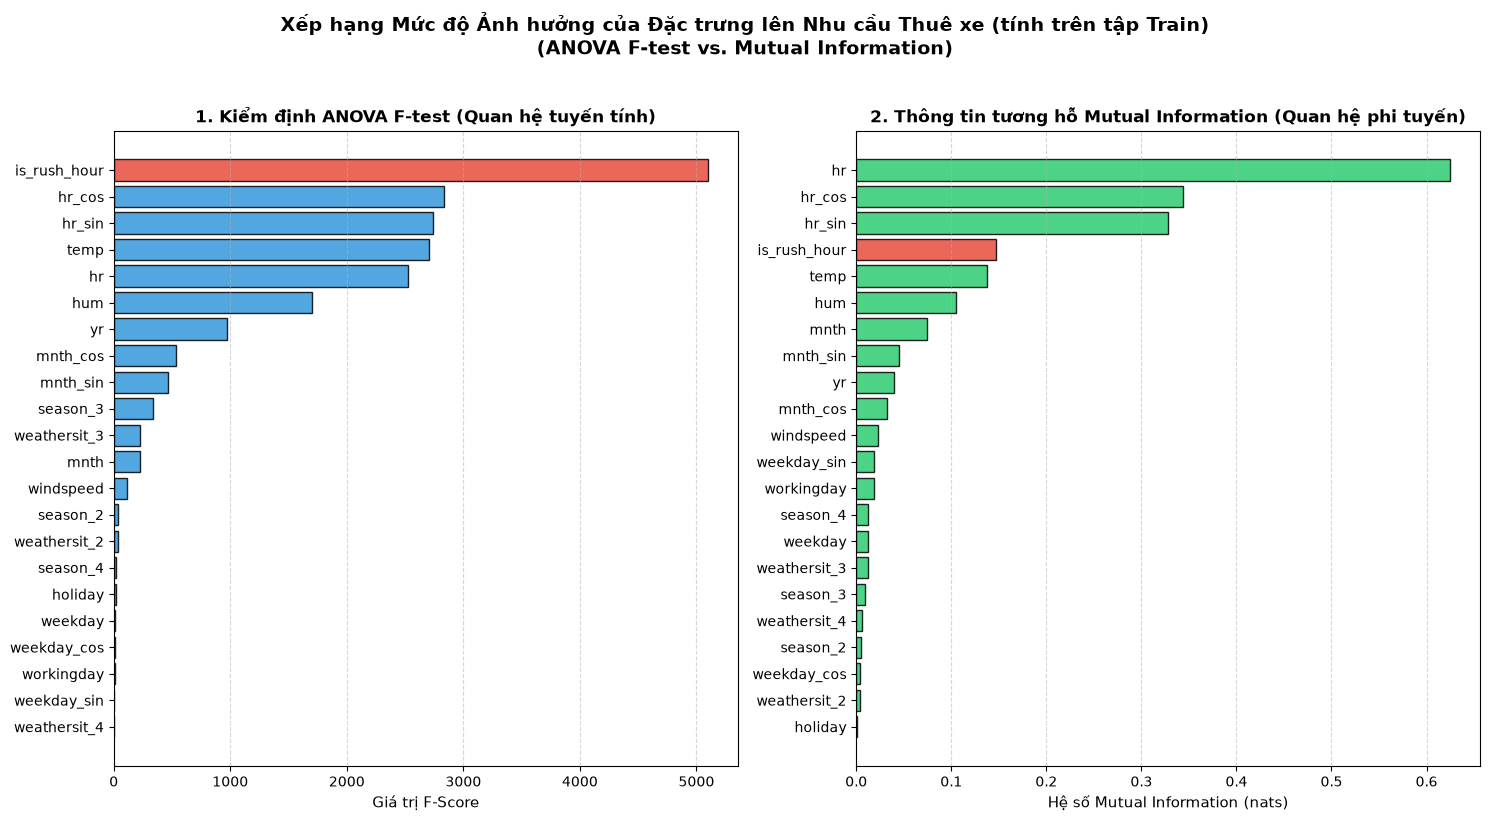

=== TOP 8 ĐẶC TRƯNG THEO F-SCORE ===
     Feature  F_Score  Mutual_Info
is_rush_hour 5097.537        0.147
      hr_cos 2831.798        0.344
      hr_sin 2739.033        0.328
        temp 2703.012        0.137
          hr 2521.953        0.625
         hum 1699.703        0.105
          yr  970.857        0.040
    mnth_cos  535.209        0.032

=== TOP 8 ĐẶC TRƯNG THEO MUTUAL INFORMATION ===
     Feature  F_Score  Mutual_Info
          hr 2521.953        0.625
      hr_cos 2831.798        0.344
      hr_sin 2739.033        0.328
is_rush_hour 5097.537        0.147
        temp 2703.012        0.137
         hum 1699.703        0.105
        mnth  229.379        0.075
    mnth_sin  463.764        0.045


In [10]:
from sklearn.feature_selection import f_regression, mutual_info_regression

f_scores, p_values = f_regression(X_train, y_train)
mi_scores = mutual_info_regression(X_train, y_train, random_state=RANDOM_STATE)

df_importance = pd.DataFrame({'Feature': X_train.columns, 'F_Score': f_scores,
                              'p_value': p_values, 'Mutual_Info': mi_scores})

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
fig.suptitle('Xếp hạng Mức độ Ảnh hưởng của Đặc trưng lên Nhu cầu Thuê xe (tính trên tập Train)\n(ANOVA F-test vs. Mutual Information)',
             fontsize=14, fontweight='bold', y=1.02)

df_f = df_importance.sort_values('F_Score', ascending=True)
colors_f = ['#e74c3c' if f == 'is_rush_hour' else '#3498db' for f in df_f['Feature']]
axes[0].barh(df_f['Feature'], df_f['F_Score'], color=colors_f, edgecolor='black', alpha=0.85)
axes[0].set_title('1. Kiểm định ANOVA F-test (Quan hệ tuyến tính)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Giá trị F-Score', fontsize=11)
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

df_mi = df_importance.sort_values('Mutual_Info', ascending=True)
colors_mi = ['#e74c3c' if f == 'is_rush_hour' else '#2ecc71' for f in df_mi['Feature']]
axes[1].barh(df_mi['Feature'], df_mi['Mutual_Info'], color=colors_mi, edgecolor='black', alpha=0.85)
axes[1].set_title('2. Thông tin tương hỗ Mutual Information (Quan hệ phi tuyến)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hệ số Mutual Information (nats)', fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../output/step2_prep_01_feature_selection.png', dpi=300, bbox_inches='tight')
plt.show()

print("=== TOP 8 ĐẶC TRƯNG THEO F-SCORE ===")
print(df_importance.sort_values('F_Score', ascending=False).head(8)[['Feature', 'F_Score', 'Mutual_Info']].round(3).to_string(index=False))
print("\n=== TOP 8 ĐẶC TRƯNG THEO MUTUAL INFORMATION ===")
print(df_importance.sort_values('Mutual_Info', ascending=False).head(8)[['Feature', 'F_Score', 'Mutual_Info']].round(3).to_string(index=False))

**Nhận xét từ kết quả kiểm định (tập Train):**
- Cả hai phương pháp đều cho thấy nhóm đặc trưng **khung giờ** (`hr`, `hr_sin`, `hr_cos`) và **nhiệt độ** (`temp`) có ảnh hưởng mạnh nhất đến nhu cầu thuê xe; độ ẩm `hum` đứng ngay sau.
- Đặc trưng do nhóm em tạo là **`is_rush_hour` có F-Score cao nhất (≈ 5.098)**, cho thấy tín hiệu giờ cao điểm có quan hệ tuyến tính rất mạnh với `cnt`.
- Ngược lại, theo Mutual Information thì `hr` dạng số nguyên đứng đầu (≈ 0.625): quan hệ giữa giờ và nhu cầu là **phi tuyến** (hai đỉnh sáng – chiều), điều mà F-test tuyến tính không phản ánh hết. Đây là lý do nhóm em giữ đồng thời `hr`, `hr_sin`, `hr_cos` và `is_rush_hour`.

# 11. Phân cụm K-Means khung giờ và Trực quan hóa bằng PCA (học trên tập Train)

1. **K-Means Clustering:** Nhóm em xây dựng hồ sơ hành vi của 24 khung giờ gồm lượng thuê trung bình chung, trung bình ngày làm việc và trung bình ngày nghỉ, **chỉ tính từ tập Train**, rồi gom thành $k=3$ cụm. Bảng ánh xạ `giờ → cụm` học từ Train được áp dụng cho cả Train và Test. Cách làm này tương tự *mã hóa theo mục tiêu (target encoding)*: hợp lệ khi chỉ dùng `cnt` của tập Train, và sẽ gây rò rỉ dữ liệu nếu dùng `cnt` của toàn bộ dữ liệu.
2. **PCA:** `StandardScaler` và PCA được **fit trên tập Train**, giảm không gian đặc trưng về 2 chiều **chỉ nhằm trực quan hóa**; hai tọa độ PCA không được đưa vào mô hình.

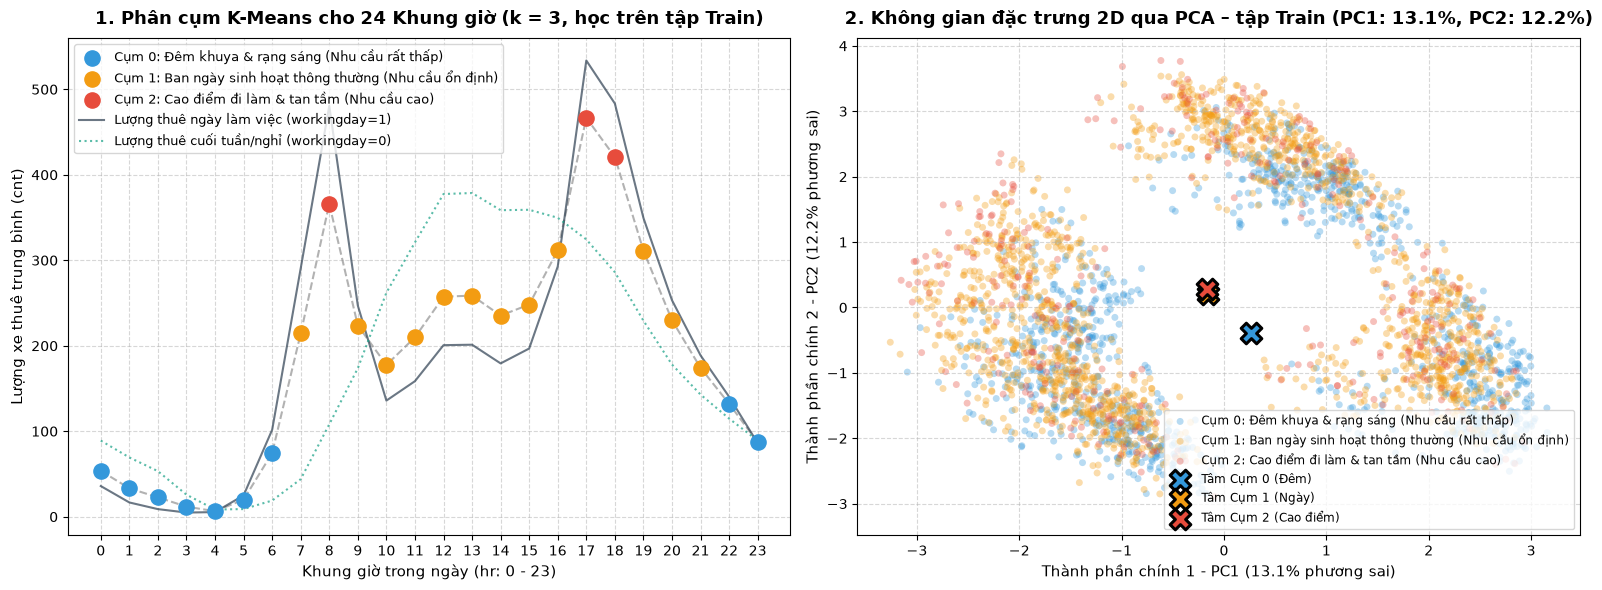

=== CÁC KHUNG GIỜ TRONG TỪNG CỤM (học từ Train) ===
Cụm 0: Đêm khuya & rạng sáng (Nhu cầu rất thấp): giờ [0, 1, 2, 3, 4, 5, 6, 22, 23] | 5167 quan sát Train (37.2%), TB 49.5 xe/giờ
Cụm 1: Ban ngày sinh hoạt thông thường (Nhu cầu ổn định): giờ [7, 9, 10, 11, 12, 13, 14, 15, 16, 19, 20, 21] | 6987 quan sát Train (50.3%), TB 238.0 xe/giờ
Cụm 2: Cao điểm đi làm & tan tầm (Nhu cầu cao): giờ [8, 17, 18] | 1749 quan sát Train (12.6%), TB 417.9 xe/giờ

Tổng phương sai giải thích bởi PC1 + PC2: 25.3%


In [11]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Hồ sơ hành vi 24 khung giờ – CHỈ từ tập Train
train_view = X_train[['hr', 'workingday']].assign(cnt=y_train)
hourly_stats = pd.DataFrame({
    'cnt_mean': train_view.groupby('hr')['cnt'].mean(),
    'cnt_workingday': train_view[train_view['workingday'] == 1].groupby('hr')['cnt'].mean(),
    'cnt_weekend': train_view[train_view['workingday'] == 0].groupby('hr')['cnt'].mean(),
}).reset_index()

scaler_h = StandardScaler()
X_h_scaled = scaler_h.fit_transform(hourly_stats[['cnt_mean', 'cnt_workingday', 'cnt_weekend']])
kmeans_h = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
hourly_stats['cluster'] = kmeans_h.fit_predict(X_h_scaled)

# Đánh lại nhãn cụm theo lượng thuê tăng dần: 0 (Thấp), 1 (Trung bình), 2 (Cao điểm)
cluster_rank = hourly_stats.groupby('cluster')['cnt_mean'].mean().sort_values().index
cluster_map = {old: new for new, old in enumerate(cluster_rank)}
hourly_stats['hour_cluster'] = hourly_stats['cluster'].map(cluster_map)
hr_to_cluster = dict(zip(hourly_stats['hr'], hourly_stats['hour_cluster']))

# Áp dụng bảng ánh xạ học từ Train cho cả Train và Test
train_cluster = X_train['hr'].map(hr_to_cluster)
test_cluster = X_test['hr'].map(hr_to_cluster)

# 2. PCA fit trên Train (chỉ để trực quan hóa)
scaler_pca = StandardScaler()
X_train_pca_in = scaler_pca.fit_transform(X_train)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_pca_in)
pca_df = pd.DataFrame(X_train_pca, columns=['pca_1', 'pca_2'], index=X_train.index)
pca_df['hour_cluster'] = train_cluster

# 3. Vẽ biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
cluster_names = {
    0: "Cụm 0: Đêm khuya & rạng sáng (Nhu cầu rất thấp)",
    1: "Cụm 1: Ban ngày sinh hoạt thông thường (Nhu cầu ổn định)",
    2: "Cụm 2: Cao điểm đi làm & tan tầm (Nhu cầu cao)"
}
colors = ["#3498db", "#f39c12", "#e74c3c"]

for c in range(3):
    sub = hourly_stats[hourly_stats['hour_cluster'] == c]
    axes[0].scatter(sub['hr'], sub['cnt_mean'], color=colors[c], s=120, zorder=5, label=cluster_names[c])
axes[0].plot(hourly_stats['hr'], hourly_stats['cnt_mean'], color='gray', linestyle='--', alpha=0.6, zorder=2)
axes[0].plot(hourly_stats['hr'], hourly_stats['cnt_workingday'], color='#2c3e50', linestyle='-', alpha=0.7, label='Lượng thuê ngày làm việc (workingday=1)', zorder=3)
axes[0].plot(hourly_stats['hr'], hourly_stats['cnt_weekend'], color='#16a085', linestyle=':', alpha=0.7, label='Lượng thuê cuối tuần/nghỉ (workingday=0)', zorder=3)
axes[0].set_title('1. Phân cụm K-Means cho 24 Khung giờ (k = 3, học trên tập Train)', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Khung giờ trong ngày (hr: 0 - 23)', fontsize=11)
axes[0].set_ylabel('Lượng xe thuê trung bình (cnt)', fontsize=11)
axes[0].set_xticks(range(0, 24))
axes[0].legend(loc='upper left', fontsize=9, frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.5)

pca_sample = pca_df.sample(n=3000, random_state=RANDOM_STATE)
for c in range(3):
    sub = pca_sample[pca_sample['hour_cluster'] == c]
    axes[1].scatter(sub['pca_1'], sub['pca_2'], color=colors[c], alpha=0.35, s=25, label=cluster_names[c], edgecolors='none')
centroids_pca = pca_df.groupby('hour_cluster')[['pca_1', 'pca_2']].mean()
centroid_names = ["Tâm Cụm 0 (Đêm)", "Tâm Cụm 1 (Ngày)", "Tâm Cụm 2 (Cao điểm)"]
for c in range(3):
    axes[1].scatter(centroids_pca.loc[c, 'pca_1'], centroids_pca.loc[c, 'pca_2'], color=colors[c], marker='X', s=220,
                    edgecolors='black', linewidth=2.2, zorder=10, label=centroid_names[c])
evr = pca.explained_variance_ratio_
axes[1].set_title(f"2. Không gian đặc trưng 2D qua PCA – tập Train (PC1: {evr[0]*100:.1f}%, PC2: {evr[1]*100:.1f}%)", fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel(f"Thành phần chính 1 - PC1 ({evr[0]*100:.1f}% phương sai)", fontsize=11)
axes[1].set_ylabel(f"Thành phần chính 2 - PC2 ({evr[1]*100:.1f}% phương sai)", fontsize=11)
axes[1].legend(loc='lower right', fontsize=8.5, frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../output/step2_prep_02_pca_kmeans.png', dpi=300, bbox_inches='tight')
plt.show()

print("=== CÁC KHUNG GIỜ TRONG TỪNG CỤM (học từ Train) ===")
for c in range(3):
    hours = sorted(hourly_stats.loc[hourly_stats['hour_cluster'] == c, 'hr'].tolist())
    n_tr = (train_cluster == c).sum()
    avg = y_train[train_cluster == c].mean()
    print(f"{cluster_names[c]}: giờ {hours} | {n_tr} quan sát Train ({n_tr/len(X_train)*100:.1f}%), TB {avg:.1f} xe/giờ")
print(f"\nTổng phương sai giải thích bởi PC1 + PC2: {evr.sum()*100:.1f}%")

**Nhận xét từ kết quả phân cụm K-Means và PCA (học trên tập Train):**
- **Cụm 0 – Đêm khuya & rạng sáng** (0h–6h, 22h–23h): 9 khung giờ, nhu cầu thấp nhất (≈ 49.5 xe/giờ).
- **Cụm 1 – Ban ngày thông thường** (7h, 9h–16h, 19h–21h): 12 khung giờ, nhu cầu ổn định (≈ 238.0 xe/giờ).
- **Cụm 2 – Cao điểm** (8h, 17h–18h): 3 khung giờ đỉnh của người đi làm, nhu cầu cao nhất (≈ 417.9 xe/giờ).
- **PCA:** PC1 và PC2 chỉ giải thích khoảng **25.3% phương sai**, nên hình chiếu 2D chỉ mang tính minh họa; các cụm có xu hướng tách theo vị trí tâm cụm nhưng vẫn chồng lấn đáng kể. Nhóm em không dùng tọa độ PCA làm đặc trưng huấn luyện.

# 12. Mã hóa One-Hot cho đặc trưng cụm `hour_cluster`

Nhãn cụm 0/1/2 là biến danh nghĩa (con số chỉ là tên cụm), nên nhóm em mã hóa One-Hot với danh mục cố định $\{0, 1, 2\}$ và `drop_first=True`, tạo hai đặc trưng `hour_cluster_1`, `hour_cluster_2` cho cả Train và Test.

In [12]:
def one_hot_cluster(cluster_series):
    cat = pd.Categorical(cluster_series, categories=[0, 1, 2])
    return pd.get_dummies(cat, prefix='hour_cluster', drop_first=True, dtype=int).set_index(cluster_series.index)

X_train = pd.concat([X_train, one_hot_cluster(train_cluster)], axis=1)
X_test = pd.concat([X_test, one_hot_cluster(test_cluster)], axis=1)

assert list(X_train.columns) == list(X_test.columns)
print(f"Số đặc trưng sau khi thêm hour_cluster: {X_train.shape[1]}")
print(list(X_train.columns))

Số đặc trưng sau khi thêm hour_cluster: 24
['yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'temp', 'hum', 'windspeed', 'hr_sin', 'hr_cos', 'mnth_sin', 'mnth_cos', 'weekday_sin', 'weekday_cos', 'is_rush_hour', 'season_2', 'season_3', 'season_4', 'weathersit_2', 'weathersit_3', 'weathersit_4', 'hour_cluster_1', 'hour_cluster_2']


# 13. Chuẩn hóa đặc trưng (Feature Scaling) và Lưu dữ liệu

- Các bộ chuẩn hóa `StandardScaler`, `MinMaxScaler`, `RobustScaler` **chỉ `.fit()` trên `X_train`**, sau đó `.transform()` cho cả `X_train` và `X_test`.
- `StandardScaler` là bộ chuẩn hóa chính cho Linear Regression, Ridge, Lasso, SVR, kNN và MLP; hai bộ còn lại làm đối chứng.
- Các tập được lưu ra `data/`:
  + `X_train.csv`, `X_test.csv`: chưa chuẩn hóa (cho các mô hình cây).
  + `X_train_scaled.csv`, `X_test_scaled.csv`: đã chuẩn hóa `StandardScaler`.
  + `y_train.csv`, `y_test.csv`: `cnt` **gốc** (mục tiêu chính).
  + `y_train_capped.csv`: `cnt` của Train đã Capping IQR theo mùa (chỉ dùng cho thí nghiệm kiểm chứng xử lý ngoại lai; luôn đánh giá trên `y_test` gốc).

In [13]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler

feature_cols = list(X_train.columns)

std_scaler = StandardScaler()
X_train_std = std_scaler.fit_transform(X_train)
X_test_std = std_scaler.transform(X_test)

minmax_scaler = MinMaxScaler()
X_train_minmax = minmax_scaler.fit_transform(X_train)
X_test_minmax = minmax_scaler.transform(X_test)

robust_scaler = RobustScaler()
X_train_robust = robust_scaler.fit_transform(X_train)
X_test_robust = robust_scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_std, columns=feature_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_std, columns=feature_cols, index=X_test.index)

data_dir = '../data'
df_export = pd.concat([X_train, X_test]).assign(cnt=pd.concat([y_train, y_test])).sort_index()
df_export.to_csv(os.path.join(data_dir, 'hour_cleaned.csv'), index=False)

X_train.to_csv(os.path.join(data_dir, 'X_train.csv'), index=False)
X_test.to_csv(os.path.join(data_dir, 'X_test.csv'), index=False)
X_train_scaled.to_csv(os.path.join(data_dir, 'X_train_scaled.csv'), index=False)
X_test_scaled.to_csv(os.path.join(data_dir, 'X_test_scaled.csv'), index=False)
y_train.rename('cnt').to_csv(os.path.join(data_dir, 'y_train.csv'), index=False)
y_test.rename('cnt').to_csv(os.path.join(data_dir, 'y_test.csv'), index=False)
y_train_capped.rename('cnt').to_csv(os.path.join(data_dir, 'y_train_capped.csv'), index=False)

print("=== THÔNG SỐ TẬP DỮ LIỆU ĐÃ LƯU ===")
print(f"X_train: {X_train.shape[0]} dòng, {X_train.shape[1]} đặc trưng | X_test: {X_test.shape[0]} dòng")
print(f"y_train (gốc) max = {y_train.max():.0f} | y_train_capped max = {y_train_capped.max():.1f} | y_test (gốc) max = {y_test.max():.0f}")
print("\n=== KIỂM CHỨNG CHUẨN HÓA (fit trên Train) ===")
print(f"X_train_scaled -> Mean: {X_train_scaled.mean().mean():.4f}, Std: {X_train_scaled.std().mean():.4f}")
print(f"X_test_scaled  -> Mean: {X_test_scaled.mean().mean():.4f}, Std: {X_test_scaled.std().mean():.4f}")
print("(Tập Test có trung bình/độ lệch chuẩn hơi khác 0/1 là bình thường, vì Scaler không được học từ Test.)")
print(f"\nDanh sách {len(feature_cols)} đặc trưng:\n{feature_cols}")

=== THÔNG SỐ TẬP DỮ LIỆU ĐÃ LƯU ===
X_train: 13903 dòng, 24 đặc trưng | X_test: 3476 dòng
y_train (gốc) max = 976 | y_train_capped max = 771.5 | y_test (gốc) max = 977

=== KIỂM CHỨNG CHUẨN HÓA (fit trên Train) ===
X_train_scaled -> Mean: 0.0000, Std: 1.0000
X_test_scaled  -> Mean: 0.0012, Std: 1.0158
(Tập Test có trung bình/độ lệch chuẩn hơi khác 0/1 là bình thường, vì Scaler không được học từ Test.)

Danh sách 24 đặc trưng:
['yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'temp', 'hum', 'windspeed', 'hr_sin', 'hr_cos', 'mnth_sin', 'mnth_cos', 'weekday_sin', 'weekday_cos', 'is_rush_hour', 'season_2', 'season_3', 'season_4', 'weathersit_2', 'weathersit_3', 'weathersit_4', 'hour_cluster_1', 'hour_cluster_2']


**Tổng kết giai đoạn Tiền xử lý dữ liệu và Kỹ thuật đặc trưng:**
1. Loại bỏ các thuộc tính định danh, rò rỉ dữ liệu (`instant`, `dteday`, `casual`, `registered`) và đa cộng tuyến (`atemp`).
2. Tạo 6 đặc trưng chu kỳ $\sin/\cos$, biến `is_rush_hour` theo quy tắc cố định, mã hóa One-Hot `season`, `weathersit` với danh mục cố định.
3. Chia Train/Test 80–20 **trước** mọi phép xử lý có học tham số.
4. Điền 22 dòng `hum == 0` bằng trung vị (tháng, giờ) học từ Train.
5. Giữ nguyên `cnt` gốc; ngưỡng IQR theo mùa chỉ học từ Train, phiên bản `y_train_capped` được lưu riêng để kiểm chứng bằng thực nghiệm.
6. Kiểm định F-test và Mutual Information, K-Means khung giờ, PCA đều chỉ học từ Train; `hour_cluster` được mã hóa One-Hot.
7. Chuẩn hóa với các Scaler chỉ fit trên Train.

**Hạn chế:** việc chia ngẫu nhiên trên dữ liệu chuỗi thời gian có thể làm kết quả đánh giá lạc quan hơn so với dự báo tương lai thực sự.